# GRB 200412B Finding Chart
This notebook generates a finding chart for GRB 200412B using the R-band observation, 
marking the target in white and reference Pan-STARRS stars in black.

In [20]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.visualization import ZScaleInterval
import astropy.units as u
from astroquery.vizier import Vizier

In [21]:
# ==========================================================
# TRIGGER TIME CALCULATION (UT to IST and Julian Date)
# ==========================================================
from astropy.time import Time, TimeDelta
import astropy.units as u

# The exact UT trigger time of the GRB (Format: YYYY-MM-DD HH:MM:SS.ss)
# For 09:08:40.71 UT on 12 April 2020:
trigger_time_str = '2020-04-12 09:08:40.71'

# Create an Astropy Time object
t_trigger_ut = Time(trigger_time_str, format='iso', scale='utc')

# IST is UT + 5 hours and 30 minutes
ist_offset = TimeDelta(5.5 * u.hour)
t_trigger_ist = t_trigger_ut + ist_offset

# Extract the Julian Date (JD)
GRB_T0_JD = t_trigger_ut.jd

print(f"GRB Trigger (UT) : {t_trigger_ut.iso}")
print(f"GRB Trigger (IST): {t_trigger_ist.iso}")
print(f"GRB Trigger (JD) : {GRB_T0_JD:.6f}")

GRB Trigger (UT) : 2020-04-12 09:08:40.710
GRB Trigger (IST): 2020-04-12 14:38:40.710
GRB Trigger (JD) : 2458951.881027


In [22]:
# ==========================================================
# GRB CORDINATE CALCULATION (Hexadecimal to Degree)
# ==========================================================
from astropy.coordinates import SkyCoord
import astropy.units as u

# You can pass the coordinate string almost exactly as it is written
coord_string = "18h33m15.21s +62d31m57.1s"

# Parse the coordinates using astropy
c = SkyCoord(coord_string, frame='icrs')

# Extract the decimal degrees
ra_decimal = c.ra.deg
dec_decimal = c.dec.deg

print(f"RA (Decimal Degrees): {ra_decimal:.6f}°")
print(f"Dec (Decimal Degrees): {dec_decimal:.6f}°")

RA (Decimal Degrees): 278.313375°
Dec (Decimal Degrees): 62.532528°


In [23]:
from astropy.coordinates import SkyCoord
import astropy.units as u

# Your GRB target coordinates
ra_deg = 278.313375
dec_deg = 62.532528

# Create a SkyCoord object
coord = SkyCoord(ra=ra_deg*u.degree, dec=dec_deg*u.degree)

# Convert to sexagesimal string (Hours:Minutes:Seconds Degrees:Minutes:Seconds)
print(coord.to_string('hmsdms'))
# Output: 18h33m15.21s +62d31m57.1008s

# If you want it separated with colons (e.g., 18:33:15.21 +62:31:57.1)
print(coord.to_string('hmsdms', sep=':'))
# Output: 18:33:15.21:+62:31:57.1008

18h33m15.21s +62d31m57.1008s
18:33:15.21 +62:31:57.1008


In [24]:
# --- Configuration ---
TARGET_NAME   = "GRB 200412B"
TARGET_RA     = 278.313375          # degrees
TARGET_DEC    = +62.532528          # degrees
IMAGE_PATH    = "1plst_R.fits"

# Vizier Pan-STARRS query settings for Zero-Point Calibration
QUERY_RADIUS_ARCMIN = 8
REF_MAG_BRIGHT      = 14.0
REF_MAG_FAINT       = 16.5
REF_MAG_ERR_MAX     = 0.05

In [25]:
# Load the image and WCS
hdul = fits.open(IMAGE_PATH)
data = hdul[0].data.astype(float)
header = hdul[0].header
wcs = WCS(header, naxis=2)
ny, nx = data.shape

# Get the center coordinates for the Vizier query
cra, cdec = wcs.wcs_pix2world(nx / 2, ny / 2, 0)
center_coord = SkyCoord(cra, cdec, unit=(u.deg, u.deg))

# Target pixel coordinates
target_x, target_y = wcs.wcs_world2pix(TARGET_RA, TARGET_DEC, 0)
target_x = float(target_x)
target_y = float(target_y)

In [26]:
# Query Pan-STARRS for reference stars
print(f"Querying Pan-STARRS (II/349/ps1) around center RA={cra:.4f}, Dec={cdec:.4f}...")
v = Vizier(columns=['RAJ2000', 'DEJ2000', 'rmag', 'e_rmag'], row_limit=5000)
result = v.query_region(center_coord, radius=QUERY_RADIUS_ARCMIN*u.arcmin, catalog='II/349/ps1')

if not result:
    raise ValueError("VizieR query returned nothing.")

catalog_table = result[0]

# Filter for good reference stars (clean, specific magnitude range)
has_valid_data = (
    ~np.ma.getmaskarray(catalog_table['rmag']) & 
    ~np.ma.getmaskarray(catalog_table['e_rmag'])
)

good_stars = catalog_table[
    has_valid_data &
    (catalog_table['rmag'] > REF_MAG_BRIGHT) & 
    (catalog_table['rmag'] < REF_MAG_FAINT) & 
    (catalog_table['e_rmag'] < REF_MAG_ERR_MAX)
]

print(f"Found {len(good_stars)} reference stars meeting the criteria.")

Querying Pan-STARRS (II/349/ps1) around center RA=278.3226, Dec=62.5397...
Found 75 reference stars meeting the criteria.


In [27]:
# Select the top 5 stars that are well within the image boundaries
margin = 150
selected_stars = []

# Sort by rmag to pick the brightest good stars, or we can just pick the first 5 
# that are isolated from the target.
good_stars.sort('rmag')

for star in good_stars:
    ra = star['RAJ2000']
    dec = star['DEJ2000']
    px, py = wcs.wcs_world2pix(ra, dec, 0)
    
    # Check if star is well within the image
    if (margin < px < nx - margin) and (margin < py < ny - margin):
        # Also ensure it's not too close to the target to avoid overlap
        dist_to_target = np.sqrt((px - target_x)**2 + (py - target_y)**2)
        if dist_to_target > 100:
            selected_stars.append({'x': float(px), 'y': float(py), 'mag': star['rmag']})
            
    if len(selected_stars) == 10:
        break

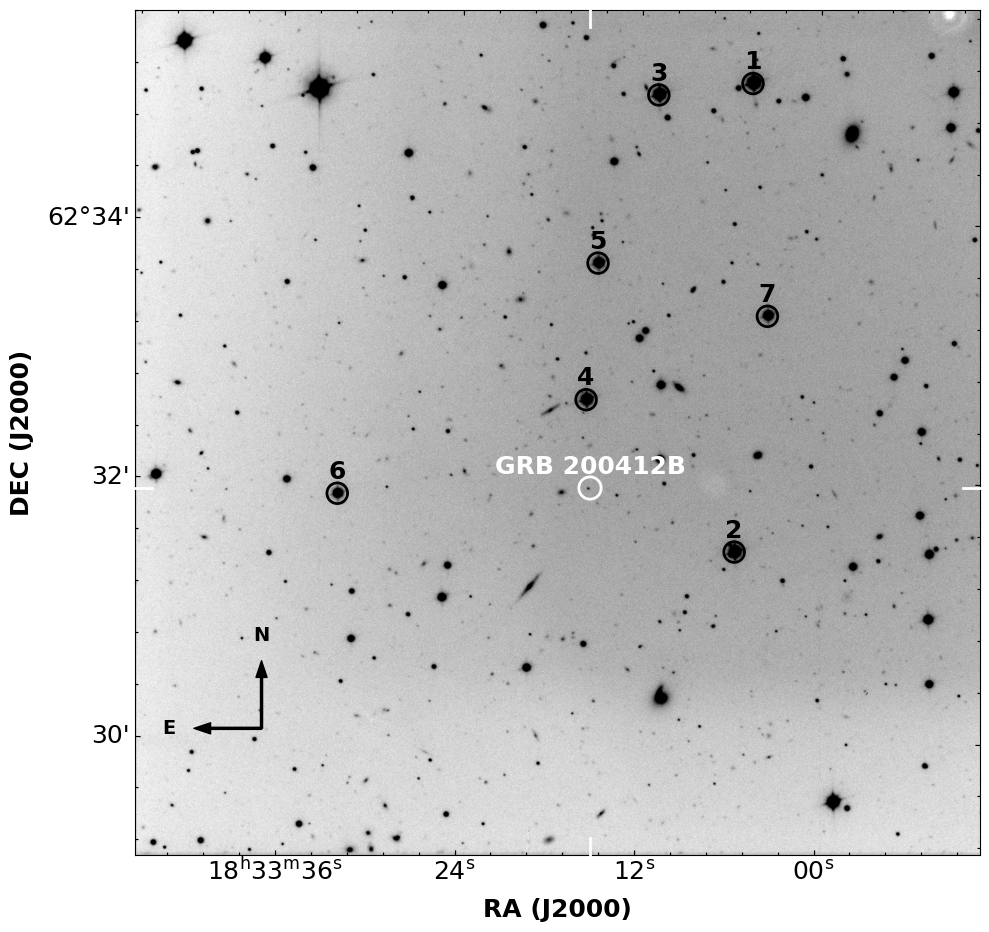

Finding chart generated and saved as 'finding_chart_GRB200412B.png'


In [ ]:
# Plot the finding chart
zscale = ZScaleInterval()
vmin, vmax = zscale.get_limits(data)

# Create figure using WCS projection
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, projection=wcs)

# Display the image (using a grayscale colormap similar to the reference)
im = ax.imshow(data, cmap='gray_r', origin='lower', vmin=vmin, vmax=vmax)

# Mark the target with a white circle
target_circle = patches.Circle((target_x, target_y), radius=27, 
                               edgecolor='white', facecolor='none', lw=3, zorder=10)
ax.add_patch(target_circle)
ax.text(target_x, target_y + 35, TARGET_NAME, 
        color='white', fontsize=18, fontweight='bold', ha='center', zorder=10)

# Mark the reference stars with black circles and numbers
for i, star in enumerate(selected_stars):
    ref_circle = patches.Circle((star['x'], star['y']), radius=25, 
                                edgecolor='black', facecolor='none', lw=2, zorder=10)
    ax.add_patch(ref_circle)
    # Put number above the circle
    ax.text(star['x'], star['y'] + 35, str(i + 1), 
            color='black', fontsize=18, fontweight='bold', ha='center', zorder=10)

# Add compass arrows (N, E) at the bottom left
x0, y0 = 0.15, 0.15 # base of the arrows in relative axes coordinates
ax.annotate('', xy=(x0, y0+0.08), xytext=(x0, y0), xycoords='axes fraction', 
            arrowprops=dict(facecolor='black', width=1.5, headwidth=8))
ax.annotate('', xy=(x0-0.08, y0), xytext=(x0, y0), xycoords='axes fraction', 
            arrowprops=dict(facecolor='black', width=1.5, headwidth=8))
# Place text slightly beyond the arrows
ax.text(x0, y0 + 0.11, 'N', transform=ax.transAxes, ha='center', va='center', fontsize=14, fontweight='bold', color='black')
ax.text(x0 - 0.11, y0, 'E', transform=ax.transAxes, ha='center', va='center', fontsize=14, fontweight='bold', color='black')

# Formatting the plot
ax.set_xlabel('RA (J2000)', fontsize=18, fontweight='bold')
ax.set_ylabel('DEC (J2000)', fontsize=18, fontweight='bold')

# Restore standard WCS ticks, point inwards, and enable minor ticks
ax.coords['ra'].set_ticks(direction='in')
ax.coords['dec'].set_ticks(direction='in')
ax.coords['ra'].display_minor_ticks(True)
ax.coords['dec'].display_minor_ticks(True)
ax.tick_params(axis='both', which='both', labelsize=18, fontweight='bold', direction='in')

# Mark the GRB position directly on the axes edges (small tick marks)
ax.plot([target_x, target_x], [0, 0.02], transform=ax.get_xaxis_transform(), color='white', lw=2, zorder=10, clip_on=False)
ax.plot([target_x, target_x], [0.98, 1.0], transform=ax.get_xaxis_transform(), color='white', lw=2, zorder=10, clip_on=False)
ax.plot([0, 0.02], [target_y, target_y], transform=ax.get_yaxis_transform(), color='white', lw=2, zorder=10, clip_on=False)
ax.plot([0.98, 1.0], [target_y, target_y], transform=ax.get_yaxis_transform(), color='white', lw=2, zorder=10, clip_on=False)

# Add text labels for the GRB RA and DEC on the axes
target_coord = SkyCoord(ra=TARGET_RA*u.degree, dec=TARGET_DEC*u.degree)
ra_str = target_coord.ra.to_string(unit=u.hour, sep='hms', precision=1)
dec_str = target_coord.dec.to_string(unit=u.degree, sep='dms', precision=1)

# ax.text(target_x, -0.015, ra_str, transform=ax.get_xaxis_transform(), ha='center', va='top', color='red', fontsize=12, fontweight='bold', clip_on=False)
# ax.text(-0.015, target_y, dec_str, transform=ax.get_yaxis_transform(), ha='right', va='center', color='red', fontsize=12, fontweight='bold', rotation=90, clip_on=False)

# Title and extra info (like date and filter)
# date_obs = header.get('DATE-OBS', 'Unknown Date').replace('T', ' ')
# telescope = header.get('TELESCOP')
# if not telescope or str(telescope).strip() == 'None':
#     telescope = '3.6m DOT'

# instrument = header.get('INSTRUME')
# if not instrument or str(instrument).strip() == 'None':
#     instrument = '4K x 4K IMAGER'

# info_text = f"{instrument} on {telescope}\n{date_obs} UTC\nR-Band"

# ax.text(0.03, 0.97, info_text, 
#         transform=ax.transAxes, color='black', fontsize=18, fontweight='bold',
#         verticalalignment='top')

plt.tight_layout()
output_filename = 'finding_chart_GRB200412B.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
plt.show()

print(f"Finding chart generated and saved as '{output_filename}'")